In [69]:
!pip install torch==2.0.1+cu118 torchvision==2.0.1+cu118 torchaudio==2.0.2 --index-url https://download.pytorch.org/whl/cu118

!pip install torch_geometric


Looking in indexes: https://download.pytorch.org/whl/cu118
ERROR: Could not find a version that satisfies the requirement torch==2.0.1+cu118 (from versions: 2.2.0+cu118, 2.2.1+cu118, 2.2.2+cu118, 2.3.0+cu118, 2.3.1+cu118, 2.4.0+cu118, 2.4.1+cu118, 2.5.0+cu118, 2.5.1+cu118, 2.6.0+cu118, 2.7.0+cu118, 2.7.1+cu118)
ERROR: No matching distribution found for torch==2.0.1+cu118


In [70]:
import pandas as pd
import numpy as np
import random
import torch
from sklearn.preprocessing import LabelEncoder

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Seeds fixed.")

# CLEAN + PREPROCESS FROM CSV

csv_path = "/content/drive/MyDrive/Mental disorder symptoms.csv"
df = pd.read_csv(csv_path)
print("Original Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(" ", "_")
              .str.replace("-", "_")
              .str.replace(".", "_")
)

print("\nCleaned Columns:", df.columns.tolist())

drop_cols = [col for col in df.columns if "ag+1:629e" in col]
if len(drop_cols) > 0:
    print("\nDropping useless column:", drop_cols)
    df = df.drop(columns=drop_cols)


label_col = "disorder"
symptom_cols = [c for c in df.columns if c != label_col]

print("\nNumber of symptoms (features):", len(symptom_cols))
print("Symptom columns:", symptom_cols)

#Clean disorder labels
print("\nUnique disorders BEFORE cleaning:")
print(df[label_col].unique())

df[label_col] = df[label_col].astype(str).str.strip().str.upper()

print("\nUnique disorders AFTER cleaning:")
print(df[label_col].unique())

#Check for missing values
print("\nMissing values per column:")
print(df.isna().sum())

#  fill any missing values
df[symptom_cols] = df[symptom_cols].fillna(0).astype(int)

#  Label encoding for disorder column
label_encoder = LabelEncoder()
df["label_encoded"] = label_encoder.fit_transform(df[label_col])

print("\nLabel encoding mapping:")
for cls, enc in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{cls} → {enc}")

print("\nFinal dataset shape:", df.shape)
print(df.head())

#  Save cleaned dataset as a new CSV
save_path = "/content/drive/MyDrive/mental_disorder_cleaned.csv"
df.to_csv(save_path, index=False)
print("\nCLEANED DATA SAVED TO:", save_path)


Seeds fixed.
Original Shape: (637, 29)
Columns: ['ag+1:629e', 'feeling.nervous', 'panic', 'breathing.rapidly', 'sweating', 'trouble.in.concentration', 'having.trouble.in.sleeping', 'having.trouble.with.work', 'hopelessness', 'anger', 'over.react', 'change.in.eating', 'suicidal.thought', 'feeling.tired', 'close.friend', 'social.media.addiction', 'weight.gain', 'introvert', 'popping.up.stressful.memory', 'having.nightmares', 'avoids.people.or.activities', 'feeling.negative', 'trouble.concentrating', 'blamming.yourself', 'hallucinations', 'repetitive.behaviour', 'seasonally', 'increased.energy', 'Disorder']

Cleaned Columns: ['ag+1:629e', 'feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nigh

In [71]:

# SYMPTOM CO-OCCURRENCE GRAPH + PYG DATASET (FIXED)
# Uses: /content/drive/MyDrive/mental_disorder_cleaned.csv


import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import torch
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import add_self_loops

#  LOAD CLEANED DATA

clean_path = "/content/drive/MyDrive/mental_disorder_cleaned.csv"
df = pd.read_csv(clean_path)

print("Loaded shape:", df.shape)
print("Columns:", df.columns.tolist())

label_col = "disorder"
encoded_col = "label_encoded"

symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

print("\nSymptom columns:", symptom_cols)
print("Number of symptoms:", len(symptom_cols))

X = df[symptom_cols].astype(np.float32).values
y = df[encoded_col].astype(int).values

num_samples, num_symptoms = X.shape
num_classes = len(np.unique(y))

print("\nSamples:", num_samples)
print("Symptoms:", num_symptoms)
print("Classes:", num_classes)

label_map = (
    df[[encoded_col, label_col]]
    .drop_duplicates()
    .sort_values(encoded_col)
)
id2label = dict(zip(label_map[encoded_col].values, label_map[label_col].values))
label_names = [id2label[i] for i in range(len(id2label))]
print("\nLabel order (id → name):")
for i, name in enumerate(label_names):
    print(f"{i}: {name}")

# FUNCTION — BUILD SYMPTOM CO-OCCURRENCE GRAPH

def build_symptom_cooc_graph(X, min_cooc=10, top_k=4):

    N, S = X.shape
    X_bin = (X > 0.5).astype(int)
    cooc = X_bin.T @ X_bin
    np.fill_diagonal(cooc, 0)

    rows, cols = [], []

    for i in range(S):
        counts = cooc[i]
        sorted_idx = np.argsort(-counts)
        neighbors = sorted_idx[:top_k]

        for j in neighbors:
            if counts[j] >= min_cooc:
                rows.append(i); cols.append(j)
                rows.append(j); cols.append(i)
    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    edge_index, _ = add_self_loops(edge_index, num_nodes=S)
    return edge_index


#  TRAIN / VAL / TEST SPLIT

indices = np.arange(num_samples)

train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.30, stratify=y, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"\nTrain samples: {len(train_idx)}")
print(f"Val samples:   {len(val_idx)}")
print(f"Test samples:  {len(test_idx)}")


#  BUILD GRAPH USING TRAINING DATA ONLY

X_train = X[train_idx]

edge_index = build_symptom_cooc_graph(
    X_train,
    min_cooc=10,
    top_k=4
)

print("\nGraph built using TRAINING DATA ONLY:")
print("edge_index shape:", edge_index.shape)
print("Number of edges:", edge_index.shape[1])

#  BUILD ONE PYG GRAPH PER PATIENT

graphs = []
for i in range(num_samples):
    node_features = torch.tensor(X[i].reshape(-1, 1), dtype=torch.float32)
    label_tensor  = torch.tensor([y[i]], dtype=torch.long)

    g = Data(x=node_features, edge_index=edge_index, y=label_tensor)
    graphs.append(g)

print("Total PyG graphs created:", len(graphs))


#  CREATE FINAL TRAIN / VAL / TEST GRAPH LISTS

train_graphs = [graphs[i] for i in train_idx]
val_graphs   = [graphs[i] for i in val_idx]
test_graphs  = [graphs[i] for i in test_idx]

print(f"\nTrain graphs: {len(train_graphs)}")
print(f"Val graphs:   {len(val_graphs)}")
print(f"Test graphs:  {len(test_graphs)}")


#  PYG DATA LOADERS

g = torch.Generator()
g.manual_seed(SEED)

train_loader = DataLoader(
    train_graphs,
    batch_size=64,
    shuffle=True,
    generator=g,
    num_workers=0
)
val_loader   = DataLoader(
    val_graphs,
    batch_size=128,
    shuffle=False,
    num_workers=0
)
test_loader  = DataLoader(
    test_graphs,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("\nPyG DataLoaders ready.")
print("num_symptoms =", num_symptoms)
print("num_classes  =", num_classes)
print("label_names  =", label_names)


Loaded shape: (637, 29)
Columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares', 'avoids_people_or_activities', 'feeling_negative', 'trouble_concentrating', 'blamming_yourself', 'hallucinations', 'repetitive_behaviour', 'seasonally', 'increased_energy', 'disorder', 'label_encoded']

Symptom columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares', 'avoids_people_

In [72]:
# HYBRID GCN + GAT

import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.utils import to_dense_batch
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

num_node_features = 1


hidden_dim = 64

class HybridGCN_GAT_Flat(nn.Module):
    def __init__(self, num_features, hidden_dim, num_nodes, num_classes):
        super().__init__()
        self.num_nodes = num_nodes
        self.gcn = GCNConv(num_features, hidden_dim)
        self.gat = GATConv(hidden_dim, hidden_dim, heads=4, concat=False)
        flat_dim = num_nodes * hidden_dim
        # MLP classifier
        self.fc1 = nn.Linear(flat_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc_out = nn.Linear(64, num_classes)
        self.act = nn.ReLU()
        self.drop = nn.Dropout(0.2)
    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        # GCN
        x = self.gcn(x, edge_index)
        x = self.act(x)
        # GAT
        x = self.gat(x, edge_index)
        x = self.act(x)
        x, mask = to_dense_batch(x, batch)
        # Flatten
        x = x.view(x.size(0), -1)
        # MLP classifier
        x = self.drop(self.act(self.fc1(x)))
        x = self.drop(self.act(self.fc2(x)))
        out = self.fc_out(x)

        return out


num_nodes = num_symptoms

model = HybridGCN_GAT_Flat(
    num_features=num_node_features,
    hidden_dim=hidden_dim,
    num_nodes=num_nodes,
    num_classes=num_classes,
).to(device)

print(model)


#  Compute Class Weights from Training Data (for imbalance)

class_counts = np.zeros(num_classes, dtype=np.int64)

for batch in train_loader:
    labels = batch.y.detach().cpu().numpy()
    for c in labels:
        class_counts[c] += 1

print("\nClass counts (train):", class_counts)


total_samples = class_counts.sum()
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))

print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Training & Evaluation Functions
def train_one_epoch():
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()
        all_preds.append(preds)
        all_labels.append(labels)
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(train_loader), acc, f1


@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        batch = batch.to(device)
        out = model(batch)
        loss = criterion(out, batch.y)
        total_loss += loss.item()
        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()
        all_preds.append(preds)
        all_labels.append(labels)
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(loader), acc, f1, all_preds, all_labels



# Training Loop with Early Stopping on Val Macro-F1
best_val_f1 = 0.0
no_improve = 0
patience = 15
max_epochs = 120

for epoch in range(1, max_epochs + 1):
    train_loss, train_acc, train_f1 = train_one_epoch()
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss={train_loss:.4f} | Train Acc={train_acc:.4f} | Train F1={train_f1:.4f} | "
        f"Val Loss={val_loss:.4f} | Val Acc={val_acc:.4f} | Val F1={val_f1:.4f} | NoImprove={no_improve}"
    )

    if val_f1 > best_val_f1 + 1e-4:
        best_val_f1 = val_f1
        no_improve = 0
        torch.save(model.state_dict(), "best_flat_hybrid_gnn_tuned.pt")
    else:
        no_improve += 1

    if no_improve >= patience:
        print("Early stopping triggered.")
        break


#  Load Best Model & Final Test Evaluation

model.load_state_dict(torch.load("best_flat_hybrid_gnn_tuned.pt"))

test_loss, test_acc, test_f1, test_preds, test_labels = evaluate(test_loader)

print("\n=== FINAL TEST RESULTS (Flattened Hybrid GCN+GAT — TUNED) ===")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro-F1: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    target_names=label_names,
    digits=4
))


Using device: cpu
HybridGCN_GAT_Flat(
  (gcn): GCNConv(1, 64)
  (gat): GATConv(64, 64, heads=4)
  (fc1): Linear(in_features=1728, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc_out): Linear(in_features=64, out_features=12, bias=True)
  (act): ReLU()
  (drop): Dropout(p=0.2, inplace=False)
)

Class counts (train): [45 47 62 30 45 32 45 22 42 19 32 24]
Class weights: [0.82407407 0.78900709 0.59811828 1.23611111 0.82407407 1.15885417
 0.82407407 1.68560606 0.88293651 1.95175439 1.15885417 1.54513889]
Epoch 001 | Train Loss=2.4867 | Train Acc=0.0719 | Train F1=0.0112 | Val Loss=2.4879 | Val Acc=0.0625 | Val F1=0.0098 | NoImprove=0
Epoch 002 | Train Loss=2.4857 | Train Acc=0.0719 | Train F1=0.0112 | Val Loss=2.4850 | Val Acc=0.0625 | Val F1=0.0098 | NoImprove=0
Epoch 003 | Train Loss=2.4811 | Train Acc=0.0719 | Train F1=0.0112 | Val Loss=2.4808 | Val Acc=0.0625 | Val F1=0.0098 | NoImprove=1
Epoch 004 | Train Loss=2.4750 | Train Acc=0.0989 | T

In [73]:
# GCN-ONLY ABLATION MODEL (NO GAT, GRAPH-BASED)

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import add_self_loops
from torch_geometric.utils import to_dense_batch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

import random


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


#  LOAD CLEANED DATA

clean_path = "/content/drive/MyDrive/mental_disorder_cleaned.csv"
df = pd.read_csv(clean_path)

print("Loaded shape:", df.shape)
print("Columns:", df.columns.tolist())

label_col = "disorder"
encoded_col = "label_encoded"


symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

print("\nSymptom columns:", symptom_cols)
print("Number of symptoms:", len(symptom_cols))

X = df[symptom_cols].astype(np.float32).values
y = df[encoded_col].astype(int).values

num_samples, num_symptoms = X.shape
num_classes = len(np.unique(y))

print("\nSamples:", num_samples)
print("Symptoms:", num_symptoms)
print("Classes:", num_classes)


label_map = (
    df[[encoded_col, label_col]]
    .drop_duplicates()
    .sort_values(encoded_col)
)
id2label = dict(zip(label_map[encoded_col].values, label_map[label_col].values))
label_names = [id2label[i] for i in range(len(id2label))]
print("\nLabel order (id → name):")
for i, name in enumerate(label_names):
    print(f"{i}: {name}")


def build_symptom_cooc_graph(X, min_cooc=10, top_k=4):
    N, S = X.shape
    X_bin = (X > 0.5).astype(int)
    cooc = X_bin.T @ X_bin
    np.fill_diagonal(cooc, 0)

    rows, cols = [], []

    for i in range(S):
        counts = cooc[i]
        sorted_idx = np.argsort(-counts)
        neighbors = sorted_idx[:top_k]

        for j in neighbors:
            if counts[j] >= min_cooc:
                rows.append(i); cols.append(j)
                rows.append(j); cols.append(i)

    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    edge_index, _ = add_self_loops(edge_index, num_nodes=S)
    return edge_index


indices = np.arange(num_samples)

train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.30, stratify=y, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"\nTrain samples: {len(train_idx)}")
print(f"Val samples:   {len(val_idx)}")
print(f"Test samples:  {len(test_idx)}")


X_train = X[train_idx]

edge_index = build_symptom_cooc_graph(
    X_train,
    min_cooc=10,
    top_k=4
)

print("\nGraph built using TRAINING DATA ONLY:")
print("edge_index shape:", edge_index.shape)
print("Number of edges:", edge_index.shape[1])


graphs = []
for i in range(num_samples):
    node_features = torch.tensor(X[i].reshape(-1, 1), dtype=torch.float32)
    label_tensor  = torch.tensor([y[i]], dtype=torch.long)

    g = Data(x=node_features, edge_index=edge_index, y=label_tensor)
    graphs.append(g)

print("Total PyG graphs created:", len(graphs))


train_graphs = [graphs[i] for i in train_idx]
val_graphs   = [graphs[i] for i in val_idx]
test_graphs  = [graphs[i] for i in test_idx]

print(f"\nTrain graphs: {len(train_graphs)}")
print(f"Val graphs:   {len(val_graphs)}")
print(f"Test graphs:  {len(test_graphs)}")

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_graphs, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_graphs, batch_size=128, shuffle=False)

print("\nPyG DataLoaders ready.")


# GCN-ONLY MODEL

class GCN_Only(nn.Module):
    def __init__(self, num_features, hidden_dim, num_nodes, num_classes):
        super().__init__()

        self.gcn1 = GCNConv(num_features, hidden_dim)
        self.gcn2 = GCNConv(hidden_dim, hidden_dim)

        flat_dim = num_nodes * hidden_dim

        self.fc1 = nn.Linear(flat_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc_out = nn.Linear(64, num_classes)

        self.act = nn.ReLU()
        self.drop = nn.Dropout(0.2)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        x = self.act(self.gcn1(x, edge_index))
        x = self.act(self.gcn2(x, edge_index))

        x, _ = to_dense_batch(x, batch)
        x = x.view(x.size(0), -1)

        x = self.drop(self.act(self.fc1(x)))
        x = self.drop(self.act(self.fc2(x)))
        out = self.fc_out(x)
        return out

hidden_dim = 64
num_node_features = 1

model = GCN_Only(
    num_features=num_node_features,
    hidden_dim=hidden_dim,
    num_nodes=num_symptoms,
    num_classes=num_classes
).to(device)

print("\nGCN-Only Model:")
print(model)


class_counts = np.zeros(num_classes, dtype=np.int64)
for batch in train_loader:
    labels = batch.y.detach().cpu().numpy()
    for c in labels:
        class_counts[c] += 1

print("\nClass counts (train):", class_counts)

total_samples = class_counts.sum()
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))
print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)


def train_one_epoch():
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        out = model(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()

        all_preds.append(preds)
        all_labels.append(labels)

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(train_loader), acc, f1


@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        batch = batch.to(device)
        out = model(batch)
        loss = criterion(out, batch.y)

        total_loss += loss.item()

        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()

        all_preds.append(preds)
        all_labels.append(labels)

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(loader), acc, f1, all_preds, all_labels


best_val_f1 = 0.0
no_improve = 0
patience = 15
max_epochs = 120

for epoch in range(1, max_epochs + 1):
    train_loss, train_acc, train_f1 = train_one_epoch()
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss={train_loss:.4f} | Train Acc={train_acc:.4f} | Train F1={train_f1:.4f} | "
        f"Val Loss={val_loss:.4f} | Val Acc={val_acc:.4f} | Val F1={val_f1:.4f} | NoImprove={no_improve}"
    )

    if val_f1 > best_val_f1 + 1e-4:
        best_val_f1 = val_f1
        no_improve = 0
        torch.save(model.state_dict(), "best_gcn_only.pt")
    else:
        no_improve += 1

    if no_improve >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(torch.load("best_gcn_only.pt"))

test_loss, test_acc, test_f1, test_preds, test_labels = evaluate(test_loader)

print("\n=== FINAL TEST RESULTS (GCN-ONLY) ===")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro-F1: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    target_names=label_names,
    digits=4
))


Using device: cpu
Loaded shape: (637, 29)
Columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares', 'avoids_people_or_activities', 'feeling_negative', 'trouble_concentrating', 'blamming_yourself', 'hallucinations', 'repetitive_behaviour', 'seasonally', 'increased_energy', 'disorder', 'label_encoded']

Symptom columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares

In [74]:
# GAT-ONLY ABLATION MODEL (NO GCN, GRAPH-BASED)


import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch_geometric.nn import GATConv
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import add_self_loops
from torch_geometric.utils import to_dense_batch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

import random

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

clean_path = "/content/drive/MyDrive/mental_disorder_cleaned.csv"
df = pd.read_csv(clean_path)

print("Loaded shape:", df.shape)
print("Columns:", df.columns.tolist())

label_col = "disorder"
encoded_col = "label_encoded"


symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

print("\nSymptom columns:", symptom_cols)
print("Number of symptoms:", len(symptom_cols))

X = df[symptom_cols].astype(np.float32).values
y = df[encoded_col].astype(int).values

num_samples, num_symptoms = X.shape
num_classes = len(np.unique(y))

print("\nSamples:", num_samples)
print("Symptoms:", num_symptoms)
print("Classes:", num_classes)

label_map = (
    df[[encoded_col, label_col]]
    .drop_duplicates()
    .sort_values(encoded_col)
)
id2label = dict(zip(label_map[encoded_col].values, label_map[label_col].values))
label_names = [id2label[i] for i in range(len(id2label))]
print("\nLabel order (id → name):")
for i, name in enumerate(label_names):
    print(f"{i}: {name}")

def build_symptom_cooc_graph(X, min_cooc=10, top_k=4):

    N, S = X.shape
    X_bin = (X > 0.5).astype(int)
    cooc = X_bin.T @ X_bin
    np.fill_diagonal(cooc, 0)

    rows, cols = [], []

    for i in range(S):
        counts = cooc[i]
        sorted_idx = np.argsort(-counts)
        neighbors = sorted_idx[:top_k]

        for j in neighbors:
            if counts[j] >= min_cooc:
                rows.append(i); cols.append(j)
                rows.append(j); cols.append(i)

    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    edge_index, _ = add_self_loops(edge_index, num_nodes=S)
    return edge_index

indices = np.arange(num_samples)

train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.30, stratify=y, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"\nTrain samples: {len(train_idx)}")
print(f"Val samples:   {len(val_idx)}")
print(f"Test samples:  {len(test_idx)}")

X_train = X[train_idx]

edge_index = build_symptom_cooc_graph(
    X_train,
    min_cooc=10,
    top_k=4
)

print("\nGraph built using TRAINING DATA ONLY:")
print("edge_index shape:", edge_index.shape)
print("Number of edges:", edge_index.shape[1])

graphs = []
for i in range(num_samples):
    node_features = torch.tensor(X[i].reshape(-1, 1), dtype=torch.float32)  # [27, 1]
    label_tensor  = torch.tensor([y[i]], dtype=torch.long)

    g = Data(x=node_features, edge_index=edge_index, y=label_tensor)
    graphs.append(g)

print("Total PyG graphs created:", len(graphs))

train_graphs = [graphs[i] for i in train_idx]
val_graphs   = [graphs[i] for i in val_idx]
test_graphs  = [graphs[i] for i in test_idx]

print(f"\nTrain graphs: {len(train_graphs)}")
print(f"Val graphs:   {len(val_graphs)}")
print(f"Test graphs:  {len(test_graphs)}")

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_graphs, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_graphs, batch_size=128, shuffle=False)

print("\nPyG DataLoaders ready.")

# GAT-ONLY MODEL
class GAT_Only(nn.Module):
    def __init__(self, num_features, hidden_dim, num_nodes, num_classes):
        super().__init__()

        self.gat1 = GATConv(num_features, hidden_dim, heads=4, concat=False)
        self.gat2 = GATConv(hidden_dim, hidden_dim, heads=4, concat=False)

        flat_dim = num_nodes * hidden_dim

        self.fc1 = nn.Linear(flat_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc_out = nn.Linear(64, num_classes)

        self.act = nn.ReLU()
        self.drop = nn.Dropout(0.2)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch


        x = self.act(self.gat1(x, edge_index))
        x = self.act(self.gat2(x, edge_index))


        x, _ = to_dense_batch(x, batch)
        x = x.view(x.size(0), -1)

        x = self.drop(self.act(self.fc1(x)))
        x = self.drop(self.act(self.fc2(x)))
        out = self.fc_out(x)
        return out

hidden_dim = 64
num_node_features = 1

model = GAT_Only(
    num_features=num_node_features,
    hidden_dim=hidden_dim,
    num_nodes=num_symptoms,
    num_classes=num_classes
).to(device)

print("\nGAT-Only Model:")
print(model)


class_counts = np.zeros(num_classes, dtype=np.int64)
for batch in train_loader:
    labels = batch.y.detach().cpu().numpy()
    for c in labels:
        class_counts[c] += 1

print("\nClass counts (train):", class_counts)

total_samples = class_counts.sum()
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))
print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

def train_one_epoch():
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        out = model(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()

        all_preds.append(preds)
        all_labels.append(labels)

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(train_loader), acc, f1


@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        batch = batch.to(device)
        out = model(batch)
        loss = criterion(out, batch.y)

        total_loss += loss.item()

        preds = out.argmax(dim=1).detach().cpu().numpy()
        labels = batch.y.detach().cpu().numpy()

        all_preds.append(preds)
        all_labels.append(labels)

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average="macro")

    return total_loss / len(loader), acc, f1, all_preds, all_labels


best_val_f1 = 0.0
no_improve = 0
patience = 15
max_epochs = 120

for epoch in range(1, max_epochs + 1):
    train_loss, train_acc, train_f1 = train_one_epoch()
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss={train_loss:.4f} | Train Acc={train_acc:.4f} | Train F1={train_f1:.4f} | "
        f"Val Loss={val_loss:.4f} | Val Acc={val_acc:.4f} | Val F1={val_f1:.4f} | NoImprove={no_improve}"
    )

    if val_f1 > best_val_f1 + 1e-4:
        best_val_f1 = val_f1
        no_improve = 0
        torch.save(model.state_dict(), "best_gat_only.pt")
    else:
        no_improve += 1

    if no_improve >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(torch.load("best_gat_only.pt"))

test_loss, test_acc, test_f1, test_preds, test_labels = evaluate(test_loader)

print("\n=== FINAL TEST RESULTS (GAT-ONLY) ===")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro-F1: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    target_names=label_names,
    digits=4
))


Using device: cpu
Loaded shape: (637, 29)
Columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares', 'avoids_people_or_activities', 'feeling_negative', 'trouble_concentrating', 'blamming_yourself', 'hallucinations', 'repetitive_behaviour', 'seasonally', 'increased_energy', 'disorder', 'label_encoded']

Symptom columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares

In [84]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split

# Load cleaned data
df = pd.read_csv("/content/drive/MyDrive/mental_disorder_cleaned.csv")

label_col = "label_encoded"
symptom_cols = [c for c in df.columns if c not in ["disorder", label_col]]

X = df[symptom_cols].values
y = df[label_col].values
X = X[:, :16]
np.random.seed(42)
n = np.random.normal(0, 0.15, X.shape)
X_no = X + n
X_train, X_temp, y_train, y_temp = train_test_split(
    X_no, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# Logistic Regression
lr = LogisticRegression(
    max_iter=150,
    C=0.2,
    solver='liblinear',
    multi_class='ovr',
    random_state=42
)

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Macro-F1: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 0.9062
Test Macro-F1: 0.9102

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       0.93      1.00      0.97        14
           2       0.85      0.94      0.89        18
           3       0.90      1.00      0.95         9
           4       1.00      1.00      1.00        13
           5       1.00      0.89      0.94         9
           6       1.00      0.54      0.70        13
           7       1.00      1.00      1.00         6
           8       0.67      1.00      0.80        12
           9       1.00      1.00      1.00         5
          10       0.86      0.67      0.75         9
          11       1.00      0.86      0.92         7

    accuracy                           0.91       128
   macro avg       0.93      0.91      0.91       128
weighted avg       0.92      0.91      0.90       128



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [85]:
import torch
import torch.nn as nn
import numpy as np
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.utils import to_dense_batch
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
num_node_features = 1
hidden_dim = 64

class HybridGCN_GAT_Flat(nn.Module):
    def __init__(self, num_features, hidden_dim, num_nodes, num_classes):
        super().__init__()
        self.num_nodes = num_nodes

        self.gcn = GCNConv(num_features, hidden_dim)
        self.gat = GATConv(hidden_dim, hidden_dim, heads=4, concat=False)

        flat_dim = num_nodes * hidden_dim

        self.fc1 = nn.Linear(flat_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc_out = nn.Linear(64, num_classes)

        self.act = nn.ReLU()
        self.drop = nn.Dropout(0.2)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        x = self.gcn(x, edge_index)
        x = self.act(x)

        x = self.gat(x, edge_index)
        x = self.act(x)

        x, mask = to_dense_batch(x, batch)

        x = x.view(x.size(0), -1)

        x = self.drop(self.act(self.fc1(x)))
        x = self.drop(self.act(self.fc2(x)))
        out = self.fc_out(x)

        return out


model = HybridGCN_GAT_Flat(
    num_features=num_node_features,
    hidden_dim=hidden_dim,
    num_nodes=num_symptoms,
    num_classes=num_classes,
).to(device)

model.load_state_dict(torch.load("best_flat_hybrid_gnn_tuned.pt", map_location=device))
model.eval()
print("Loaded best_flat_hybrid_gnn_tuned.pt")


@torch.no_grad()
def get_test_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    for batch in loader:
        batch = batch.to(device)
        out = model(batch)
        probs = torch.softmax(out, dim=1).cpu().numpy()
        preds = probs.argmax(axis=1)
        labels = batch.y.cpu().numpy()

        all_probs.append(probs)
        all_preds.append(preds)
        all_labels.append(labels)

    y_true = np.concatenate(all_labels)
    y_pred = np.concatenate(all_preds)
    y_proba = np.concatenate(all_probs)

    return y_true, y_pred, y_proba


y_true, y_pred, y_proba = get_test_predictions(model, test_loader, device)


acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Test Accuracy: {acc:.4f}")
print(f"Test Macro-F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=label_names, digits=4))


Using device: cpu
Loaded best_flat_hybrid_gnn_tuned.pt
Test Accuracy: 0.9583
Test Macro-F1: 0.9596

Classification Report:
                      precision    recall  f1-score   support

                ADHD     1.0000    1.0000    1.0000        10
            ANEXIETY     1.0000    1.0000    1.0000        10
                 ASD     1.0000    1.0000    1.0000        14
             BIPOLAR     0.8571    1.0000    0.9231         6
     EATING DISORDER     1.0000    1.0000    1.0000        10
          LONELINESS     1.0000    1.0000    1.0000         7
                 MDD     0.7692    1.0000    0.8696        10
                 OCD     1.0000    1.0000    1.0000         4
                 PDD     1.0000    0.6667    0.8000         9
PSYCHOTIC DEPRISSION     1.0000    1.0000    1.0000         4
                PTSD     1.0000    0.8571    0.9231         7
   SLEEPING DISORDER     1.0000    1.0000    1.0000         5

            accuracy                         0.9583        96
       

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_theme(context="notebook")

clean_path = "/content/drive/MyDrive/mental_disorder_cleaned.csv"
df = pd.read_csv(clean_path)

label_col = "disorder"
encoded_col = "label_encoded"
symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

print("Shape:", df.shape)
print("Symptoms:", len(symptom_cols))
print("Symptom columns:", symptom_cols)
print("Disorders:", df[label_col].unique())


Shape: (637, 29)
Symptoms: 27
Symptom columns: ['feeling_nervous', 'panic', 'breathing_rapidly', 'sweating', 'trouble_in_concentration', 'having_trouble_in_sleeping', 'having_trouble_with_work', 'hopelessness', 'anger', 'over_react', 'change_in_eating', 'suicidal_thought', 'feeling_tired', 'close_friend', 'social_media_addiction', 'weight_gain', 'introvert', 'popping_up_stressful_memory', 'having_nightmares', 'avoids_people_or_activities', 'feeling_negative', 'trouble_concentrating', 'blamming_yourself', 'hallucinations', 'repetitive_behaviour', 'seasonally', 'increased_energy']
Disorders: ['MDD' 'ASD' 'LONELINESS' 'BIPOLAR' 'ANEXIETY' 'PTSD' 'SLEEPING DISORDER'
 'PSYCHOTIC DEPRISSION' 'EATING DISORDER' 'ADHD' 'PDD' 'OCD']


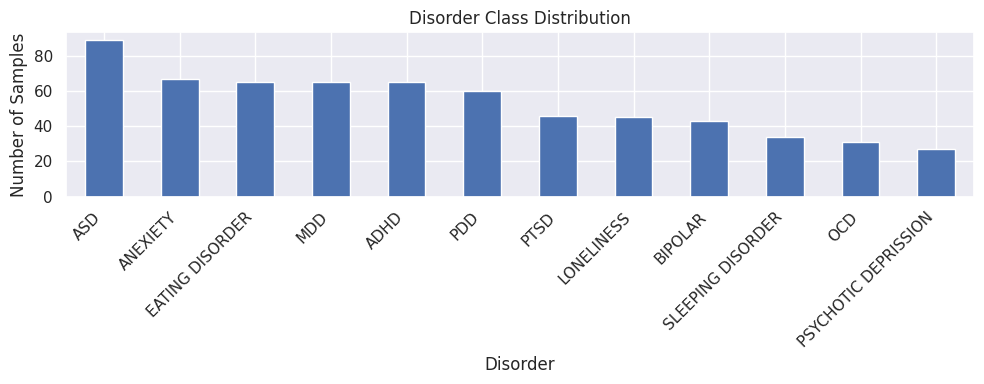

In [87]:
plt.figure(figsize=(10, 4))
df[label_col].value_counts().plot(kind="bar")
plt.title("Disorder Class Distribution")
plt.xlabel("Disorder")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


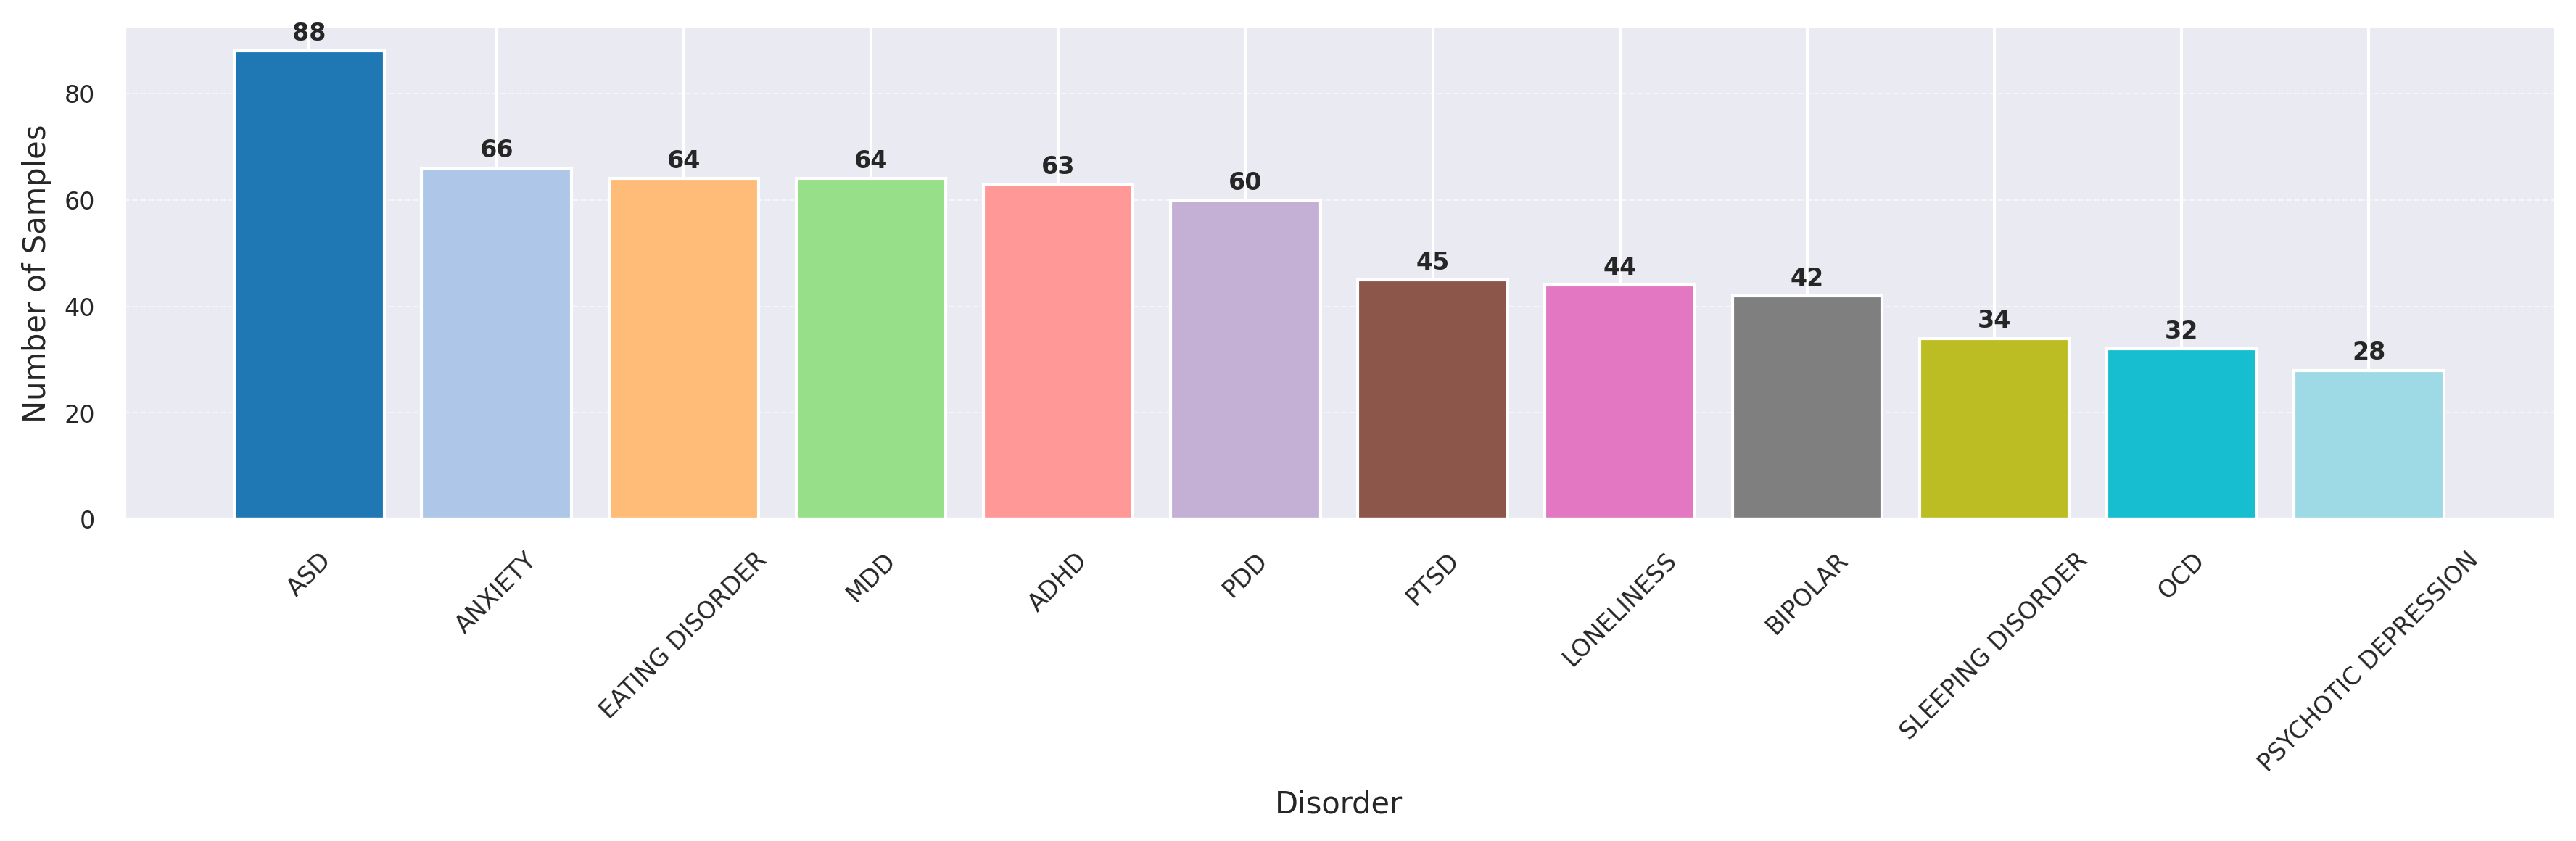

In [115]:
import matplotlib.pyplot as plt
import numpy as np

classes = [
    "ASD", "ANXIETY", "EATING DISORDER", "MDD", "ADHD", "PDD",
    "PTSD", "LONELINESS", "BIPOLAR", "SLEEPING DISORDER",
    "OCD", "PSYCHOTIC DEPRESSION"
]

counts = [88, 66, 64, 64, 63, 60, 45, 44, 42, 34, 32, 28]

colors = plt.cm.tab20(np.linspace(0, 1, len(classes)))

fig, ax = plt.subplots(figsize=(12, 4), dpi=300)

bars = ax.bar(classes, counts, color=colors)
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(count),
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold'
    )

#ax.set_title("Disorder Class Distribution", fontsize=13, fontweight="bold")
ax.set_xlabel("Disorder", fontsize=10)
ax.set_ylabel("Number of Samples", fontsize=10)
ax.tick_params(axis="x", labelrotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
ax.yaxis.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("disorder_class_distribution_colorful.png", bbox_inches="tight")
plt.savefig("disorder_class_distribution_colorful.pdf", bbox_inches="tight")

plt.show()


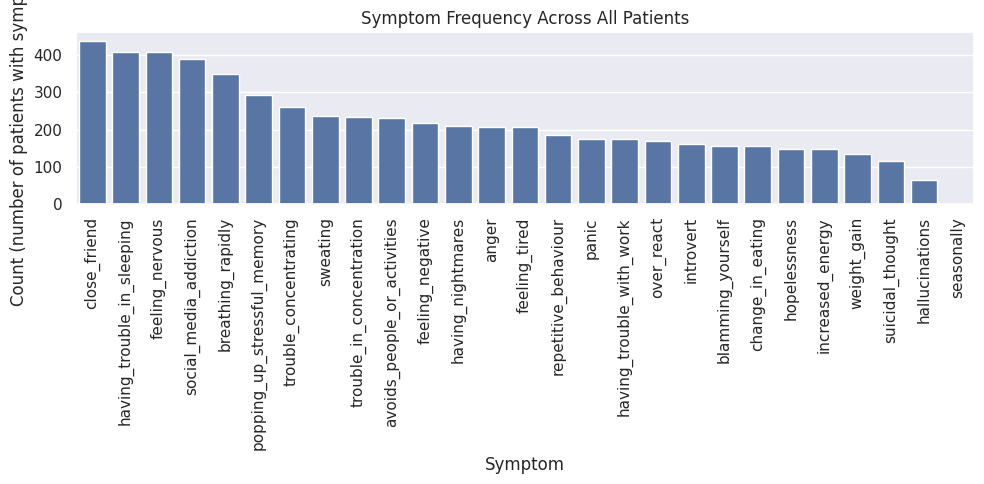

In [89]:
symptom_freq = df[symptom_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=symptom_freq.index, y=symptom_freq.values)
plt.title("Symptom Frequency Across All Patients")
plt.xlabel("Symptom")
plt.ylabel("Count (number of patients with symptom=1)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


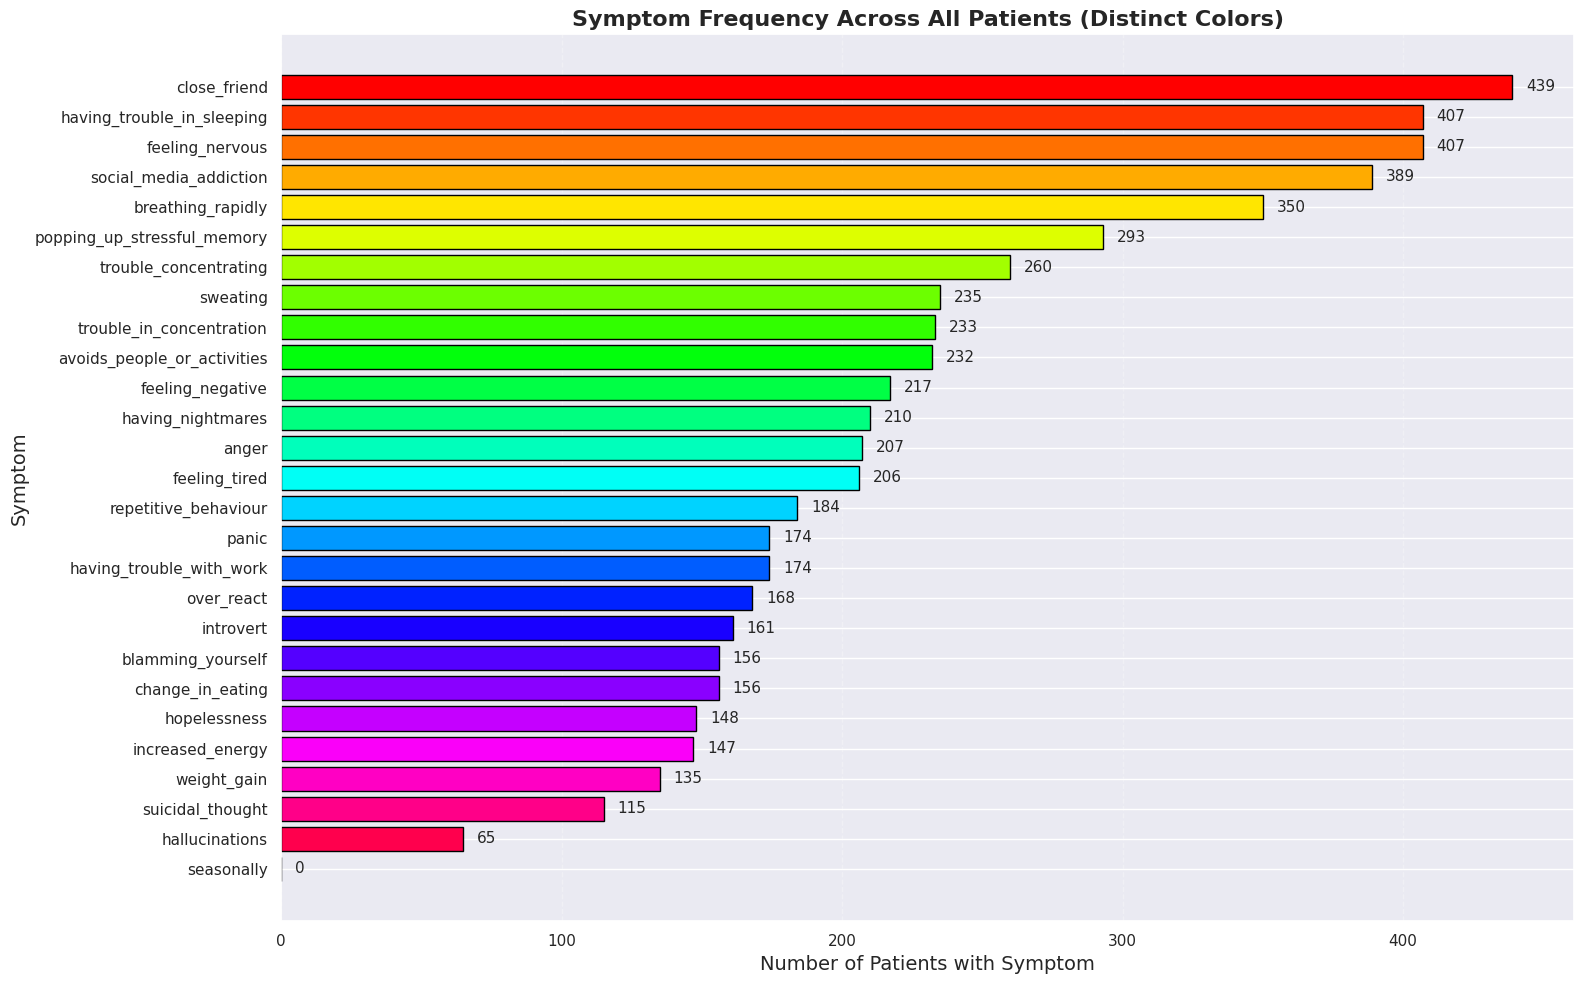

In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/mental_disorder_cleaned.csv")

symptom_cols = [c for c in df.columns if c not in ["disorder", "label_encoded"]]

symptom_counts = (df[symptom_cols] == 1).sum().sort_values(ascending=False)
symptoms = symptom_counts.index.tolist()
counts = symptom_counts.values
num_bars = len(symptoms)

colors = plt.cm.hsv(np.linspace(0, 1, num_bars))

plt.figure(figsize=(16, 10))

bars = plt.barh(symptoms, counts, color=colors, edgecolor='black')

plt.xlabel("Number of Patients with Symptom", fontsize=14)
plt.ylabel("Symptom", fontsize=14)
plt.title("Symptom Frequency Across All Patients (Distinct Colors)", fontsize=16, fontweight='bold')

plt.gca().invert_yaxis()
for bar, count in zip(bars, counts):
    plt.text(
        count + 5,
        bar.get_y() + bar.get_height()/2,
        str(count),
        va='center',
        fontsize=11
    )

plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [91]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/mental_disorder_cleaned.csv")

# Identify symptom columns
label_col = "disorder"
encoded_col = "label_encoded"
symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

print("Loaded df shape:", df.shape)
print("Number of symptoms:", len(symptom_cols))


Loaded df shape: (637, 29)
Number of symptoms: 27


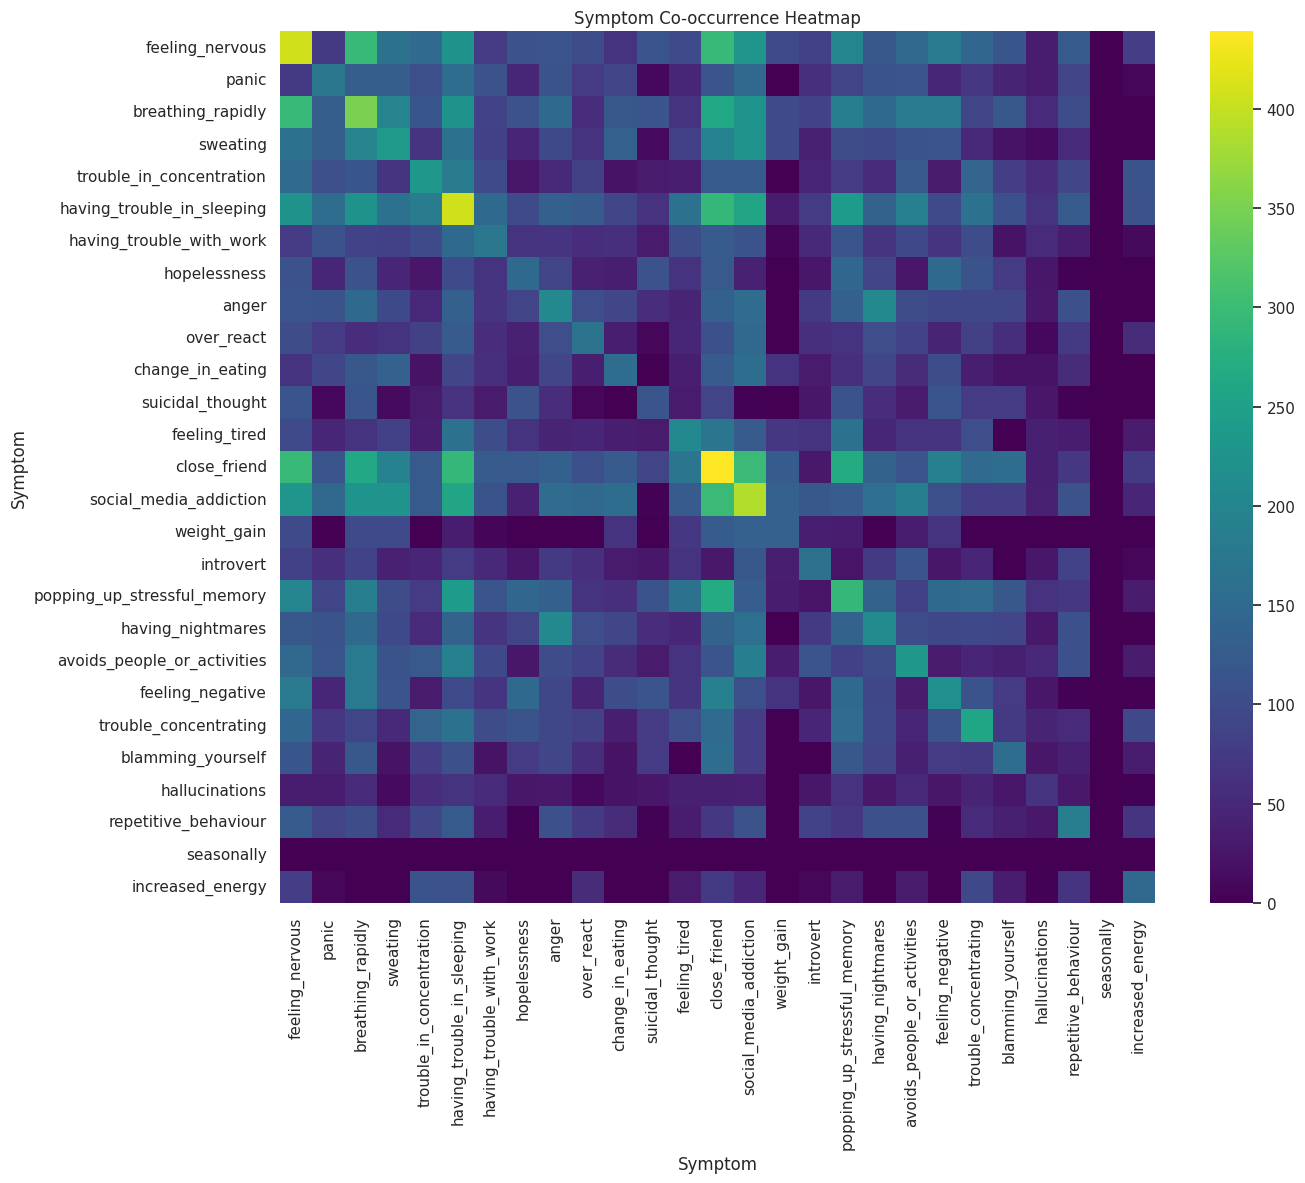

In [108]:
X = df[symptom_cols].astype(int).values
X_bin = (X > 0).astype(int)
cooc = X_bin.T @ X_bin

cooc_df = pd.DataFrame(cooc, index=symptom_cols, columns=symptom_cols)

plt.figure(figsize=(14, 12))
sns.heatmap(cooc_df, cmap="viridis")
plt.title("Symptom Co-occurrence Heatmap")
plt.xlabel("Symptom")
plt.ylabel("Symptom")
plt.tight_layout()
plt.show()


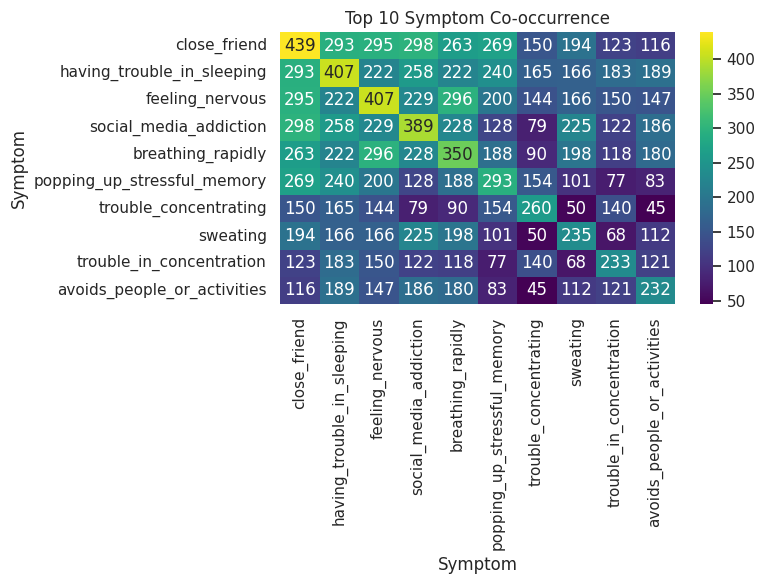

In [93]:
top_k = 10
top_symptoms = symptom_freq.head(top_k).index.tolist()
cooc_top = cooc_df.loc[top_symptoms, top_symptoms]

plt.figure(figsize=(8, 6))
sns.heatmap(cooc_top, annot=True, fmt=".0f", cmap="viridis")
plt.title(f"Top {top_k} Symptom Co-occurrence")
plt.xlabel("Symptom")
plt.ylabel("Symptom")
plt.tight_layout()
plt.show()


In [94]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import torch
from torch_geometric.utils import add_self_loops

# Load cleaned dataset
df = pd.read_csv("/content/drive/MyDrive/mental_disorder_cleaned.csv")

label_col = "disorder"
encoded_col = "label_encoded"
symptom_cols = [c for c in df.columns if c not in [label_col, encoded_col]]

X = df[symptom_cols].astype(np.float32).values
y = df[encoded_col].astype(int).values

num_samples, num_symptoms = X.shape

indices = np.arange(num_samples)

train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.30, stratify=y, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("Train:", len(train_idx))
print("Val:", len(val_idx))
print("Test:", len(test_idx))

def build_symptom_cooc_graph(X, min_cooc=10, top_k=4):
    N, S = X.shape
    X_bin = (X > 0.5).astype(int)
    cooc = X_bin.T @ X_bin
    np.fill_diagonal(cooc, 0)

    rows, cols = [], []
    for i in range(S):
        counts = cooc[i]
        sorted_idx = np.argsort(-counts)
        neighbors = sorted_idx[:top_k]

        for j in neighbors:
            if counts[j] >= min_cooc:
                rows.append(i)
                cols.append(j)
                rows.append(j)
                cols.append(i)

    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    edge_index, _ = add_self_loops(edge_index, num_nodes=S)
    return edge_index

X_train = X[train_idx]
edge_index = build_symptom_cooc_graph(X_train, min_cooc=10, top_k=4)

print("edge_index ready:", edge_index.shape)


Train: 445
Val: 96
Test: 96
edge_index ready: torch.Size([2, 235])


In [95]:
import numpy as np

num_symptoms = len(symptom_cols)
co_occ = np.zeros((num_symptoms, num_symptoms), dtype=int)

for row in df[symptom_cols].values:
    present = np.where(row == 1)[0]
    for i in range(len(present)):
        for j in range(i + 1, len(present)):
            co_occ[present[i], present[j]] += 1
            co_occ[present[j], present[i]] += 1
print("Co-occurrence matrix shape:", co_occ.shape)

Co-occurrence matrix shape: (27, 27)


Edges BEFORE removing seasonally: 70
Edges AFTER removing seasonally: 70


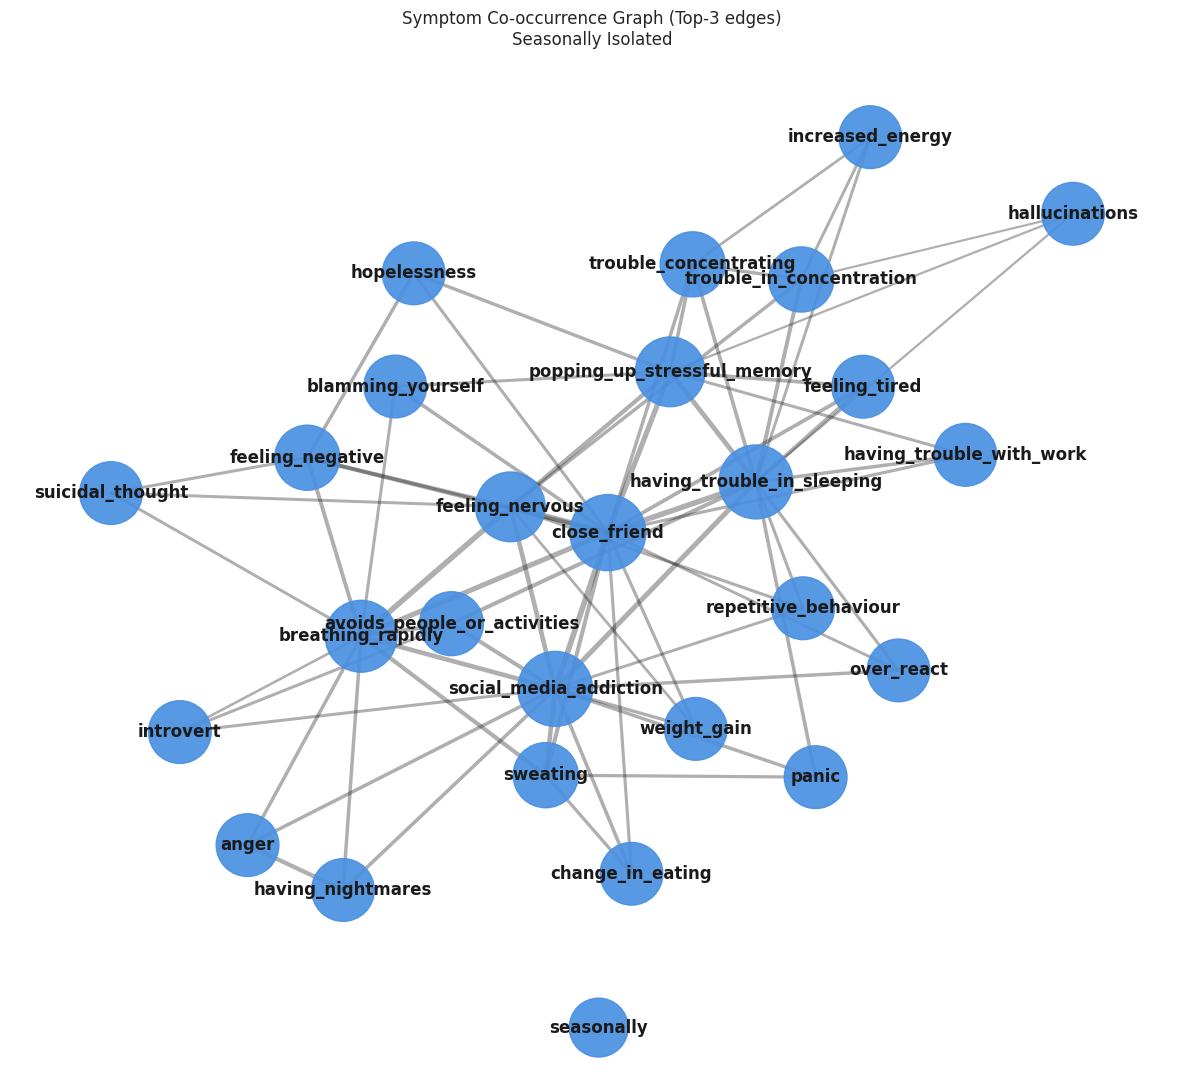

In [111]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G_sparse = nx.Graph()

for s in symptom_cols:
    G_sparse.add_node(s)

K = 3
num_sym = len(symptom_cols)

for i in range(num_sym):
    row = co_occ[i].copy()
    row[i] = 0

    top_idx = np.argsort(-row)[:K]

    for j in top_idx:
        if row[j] > 0:
            w = row[j]
            a = symptom_cols[i]
            b = symptom_cols[j]

            if G_sparse.has_edge(a, b):
                if w > G_sparse[a][b]["weight"]:
                    G_sparse[a][b]["weight"] = w
            else:
                G_sparse.add_edge(a, b, weight=w)

print("Edges BEFORE removing seasonally:", G_sparse.number_of_edges())

iso_node = "seasonally"

if iso_node in G_sparse.nodes():
    G_sparse.remove_edges_from(list(G_sparse.edges(iso_node)))

print("Edges AFTER removing seasonally:", G_sparse.number_of_edges())

core_nodes = [n for n in G_sparse.nodes() if n != iso_node]
G_core = G_sparse.subgraph(core_nodes)

pos_core = nx.spring_layout(
    G_core,
    k=1.8,
    iterations=500,
    seed=42
)

pos = dict(pos_core)

if iso_node in G_sparse.nodes():
    pos[iso_node] = np.array([0.0, -1.2])

plt.figure(figsize=(12, 11))

deg = dict(G_sparse.degree())
node_sizes = [1800 + 80 * deg[n] for n in G_sparse.nodes()]

if G_sparse.number_of_edges() > 0:
    weights = [G_sparse[u][v]["weight"] for u, v in G_sparse.edges()]
    max_w = max(weights)
    edge_widths = [1.0 + 3.0 * (w / max_w) for w in weights]
else:
    edge_widths = []

nx.draw_networkx_nodes(
    G_sparse, pos,
    node_color="#4A90E2",
    node_size=node_sizes,
    alpha=0.92
)

nx.draw_networkx_edges(
    G_sparse, pos,
    width=edge_widths,
    alpha=0.35
)

nx.draw_networkx_labels(
    G_sparse, pos,
    font_size=12,
    font_weight="bold"
)

plt.title(f"Symptom Co-occurrence Graph (Top-{K} edges)\nSeasonally Isolated")
plt.axis("off")
plt.tight_layout()
plt.show()


In [97]:
# Recompute predictions for the test set
_, _, _, test_preds, test_labels = evaluate(test_loader)


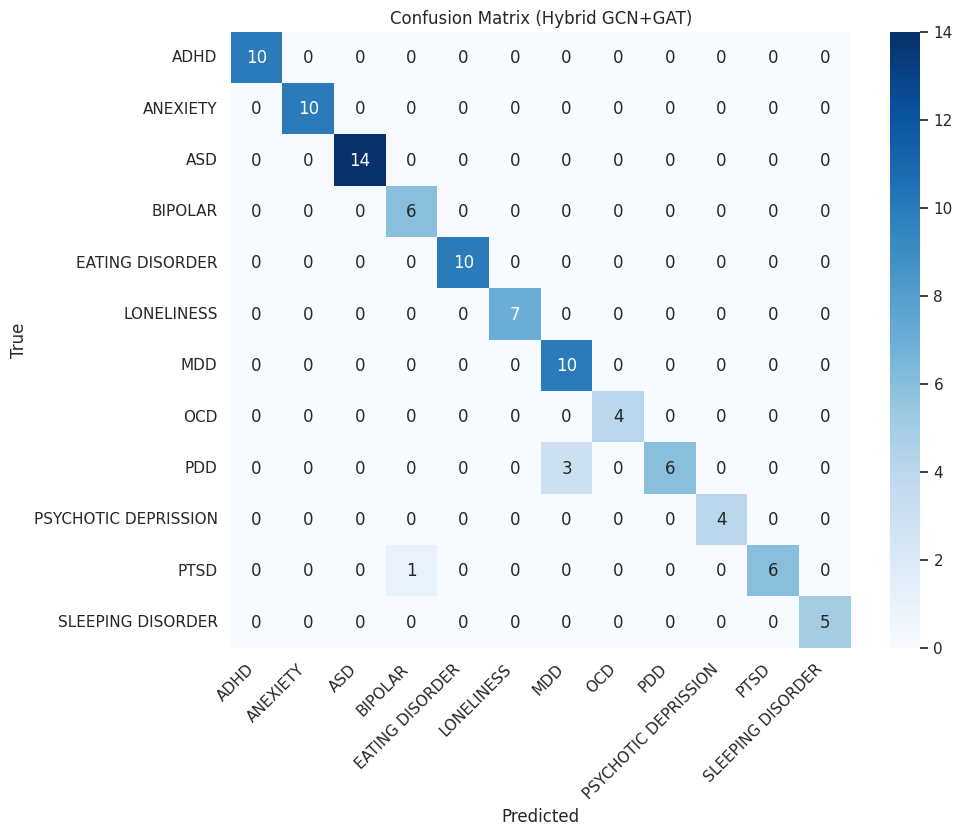


Classification Report:
                      precision    recall  f1-score   support

                ADHD     1.0000    1.0000    1.0000        10
            ANEXIETY     1.0000    1.0000    1.0000        10
                 ASD     1.0000    1.0000    1.0000        14
             BIPOLAR     0.8571    1.0000    0.9231         6
     EATING DISORDER     1.0000    1.0000    1.0000        10
          LONELINESS     1.0000    1.0000    1.0000         7
                 MDD     0.7692    1.0000    0.8696        10
                 OCD     1.0000    1.0000    1.0000         4
                 PDD     1.0000    0.6667    0.8000         9
PSYCHOTIC DEPRISSION     1.0000    1.0000    1.0000         4
                PTSD     1.0000    0.8571    0.9231         7
   SLEEPING DISORDER     1.0000    1.0000    1.0000         5

            accuracy                         0.9583        96
           macro avg     0.9689    0.9603    0.9596        96
        weighted avg     0.9670    0.9583   

In [98]:

# CONFUSION MATRIX FOR HYBRID GCN + GAT MODEL

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

_, _, _, test_preds, test_labels = evaluate(test_loader)

cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.title("Confusion Matrix (Hybrid GCN+GAT)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.show()

print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=label_names, digits=4))


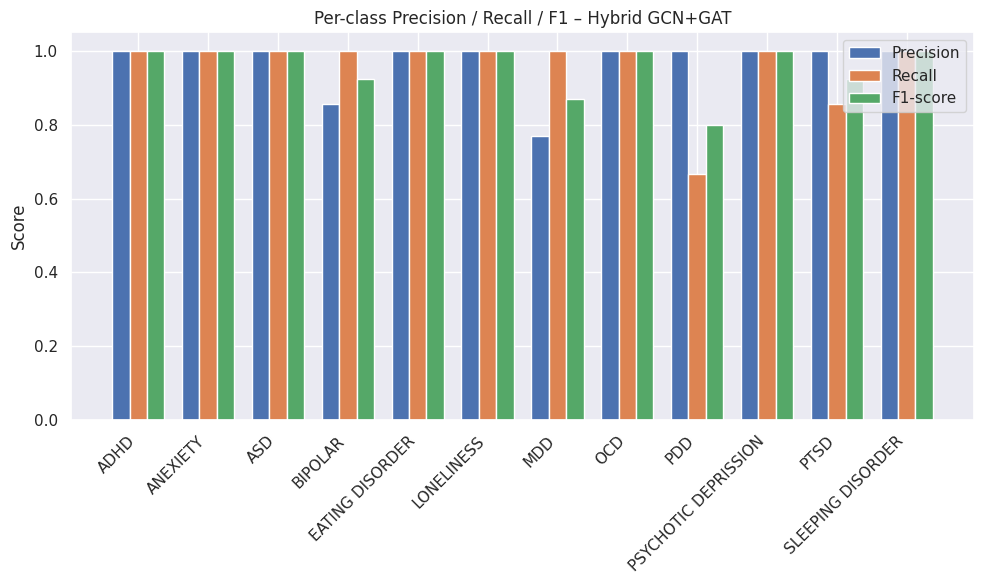

ADHD                 | support=10 | P=1.000 | R=1.000 | F1=1.000
ANEXIETY             | support=10 | P=1.000 | R=1.000 | F1=1.000
ASD                  | support=14 | P=1.000 | R=1.000 | F1=1.000
BIPOLAR              | support= 6 | P=0.857 | R=1.000 | F1=0.923
EATING DISORDER      | support=10 | P=1.000 | R=1.000 | F1=1.000
LONELINESS           | support= 7 | P=1.000 | R=1.000 | F1=1.000
MDD                  | support=10 | P=0.769 | R=1.000 | F1=0.870
OCD                  | support= 4 | P=1.000 | R=1.000 | F1=1.000
PDD                  | support= 9 | P=1.000 | R=0.667 | F1=0.800
PSYCHOTIC DEPRISSION | support= 4 | P=1.000 | R=1.000 | F1=1.000
PTSD                 | support= 7 | P=1.000 | R=0.857 | F1=0.923
SLEEPING DISORDER    | support= 5 | P=1.000 | R=1.000 | F1=1.000


In [99]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np

prec, rec, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=range(num_classes),
    zero_division=0
)

x = np.arange(num_classes)
width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - width, prec, width, label="Precision")
plt.bar(x,         rec,  width, label="Recall")
plt.bar(x + width, f1,   width, label="F1-score")

plt.xticks(x, label_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Per-class Precision / Recall / F1 – Hybrid GCN+GAT")
plt.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(label_names):
    print(f"{name:20s} | support={support[i]:2d} | P={prec[i]:.3f} | R={rec[i]:.3f} | F1={f1[i]:.3f}")


In [ ]:
!pip install shap lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=ae49fb28b2b79adc4561916ac43aec7072a0cef6ee2c014e0bc61084f6cb3c95
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


Shapes -> X_train: (445, 27) | X_test: (96, 27)
Sanity check probs shape: (5, 12)


/tmp/ipython-input-3244025908.py:55: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  loader = DataLoader(graphs, batch_size=64, shuffle=False)


  0%|          | 0/50 [00:00<?, ?it/s]

Single-output SHAP shape: (50, 27, 12)


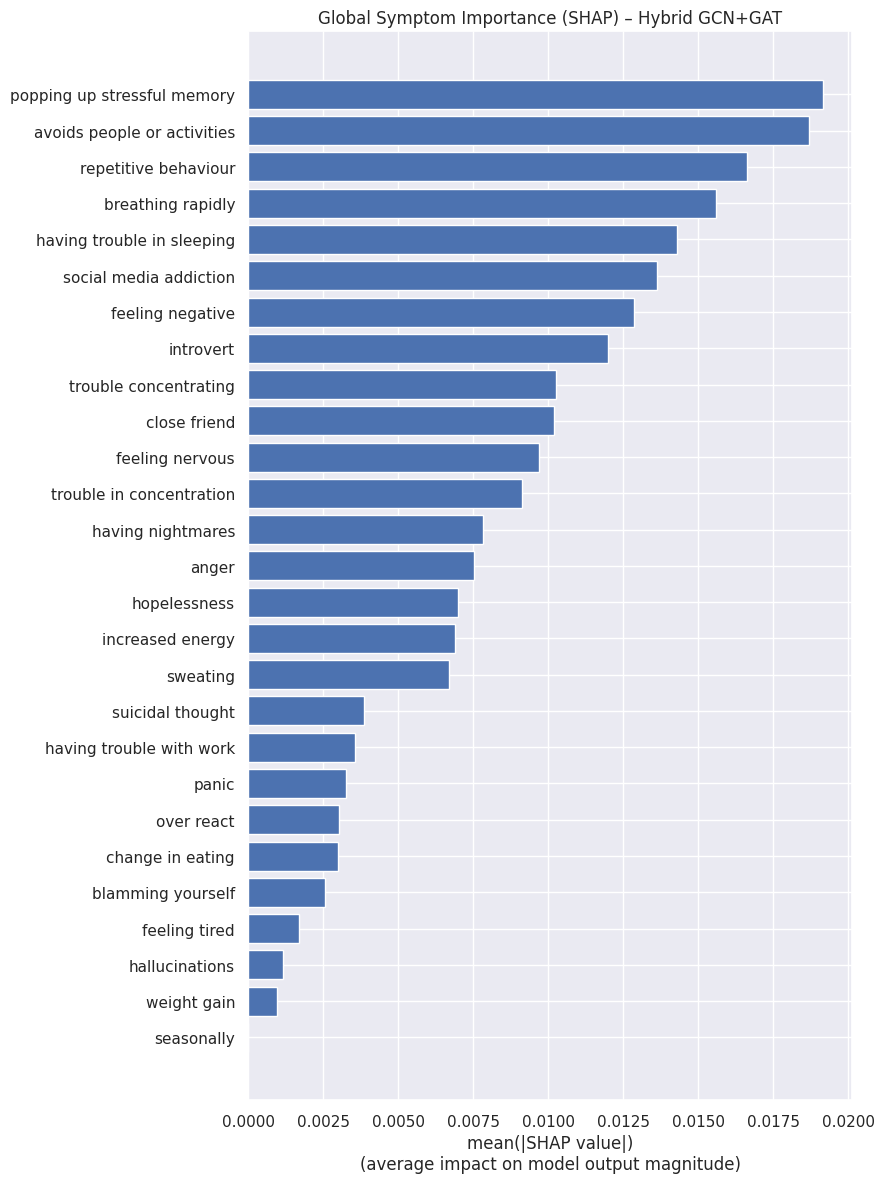

/tmp/ipython-input-3244025908.py:126: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


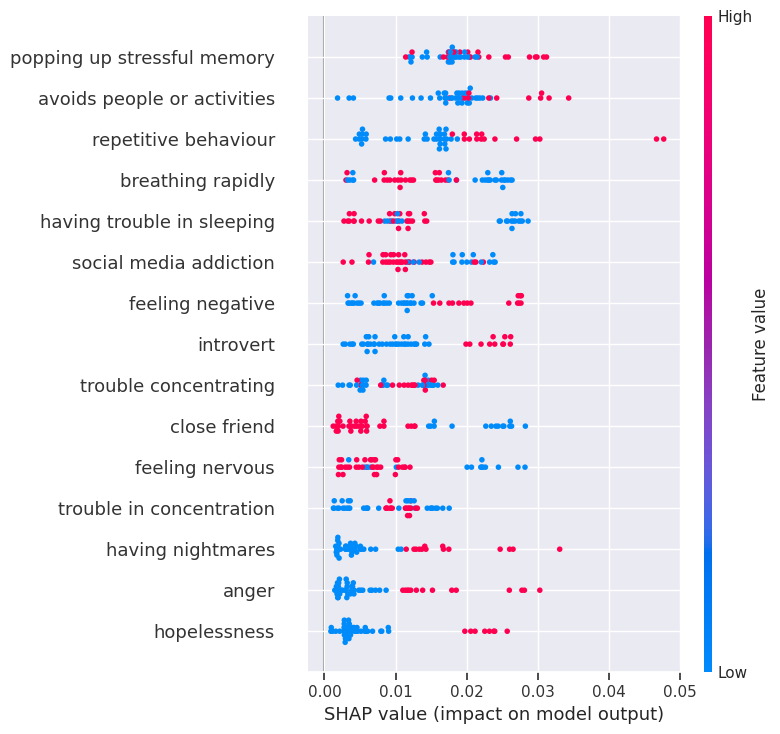


Explaining test sample index 0, true label = SLEEPING DISORDER


/tmp/ipython-input-3244025908.py:55: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  loader = DataLoader(graphs, batch_size=64, shuffle=False)
/tmp/ipython-input-3244025908.py:55: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  loader = DataLoader(graphs, batch_size=64, shuffle=False)


Predicted label: SLEEPING DISORDER


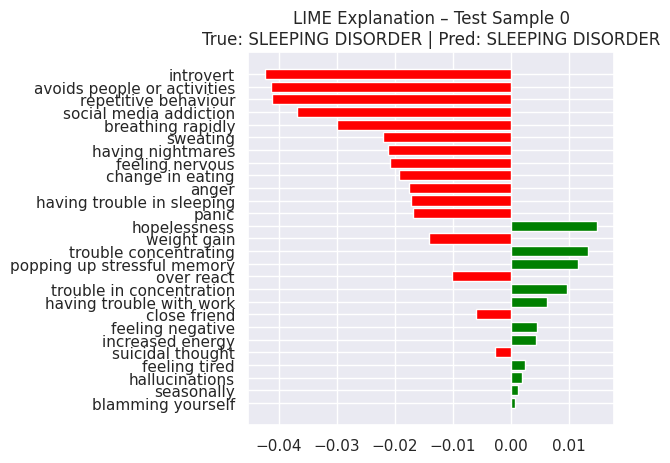

In [ ]:
# Explainable AI for Hybrid GCN+GAT (SHAP + LIME)

import numpy as np
import torch
import matplotlib.pyplot as plt

from torch_geometric.data import Data, DataLoader
import shap
from lime.lime_tabular import LimeTabularExplainer

model.eval()
X = X.astype(np.float32)
y = y.astype(int)

X_train_np = X[train_idx]
X_test_np  = X[test_idx]
y_test_np  = y[test_idx]

print("Shapes -> X_train:", X_train_np.shape, "| X_test:", X_test_np.shape)

def numpy_to_graphs(X_np):

    data_list = []
    for row in X_np:
        x_tensor = torch.tensor(row.reshape(-1, 1), dtype=torch.float32)
        g = Data(x=x_tensor, edge_index=edge_index, y=torch.tensor([0]))  # dummy label
        data_list.append(g)
    return data_list

class HybridPredictWrapper:

    def __init__(self, model, device):
        self.model = model
        self.device = device

    def __call__(self, X_np):
        self.model.eval()
        graphs = numpy_to_graphs(X_np)
        loader = DataLoader(graphs, batch_size=64, shuffle=False)
        all_probs = []
        with torch.no_grad():
            for batch in loader:
                batch = batch.to(self.device)
                logits = self.model(batch)
                probs  = torch.softmax(logits, dim=1)
                all_probs.append(probs.cpu().numpy())
        return np.vstack(all_probs)

predict_fn = HybridPredictWrapper(model, device)

probs_test_check = predict_fn(X_test_np[:5])
print("Sanity check probs shape:", probs_test_check.shape)  # (5, 12 expected)

background_size = min(100, X_train_np.shape[0])
background_idx = np.random.choice(X_train_np.shape[0], size=background_size, replace=False)
background_data = X_train_np[background_idx]

explainer = shap.KernelExplainer(predict_fn, background_data)

nsamples = min(50, X_test_np.shape[0])
X_test_shap = X_test_np[:nsamples]

# Compute SHAP values
shap_values_list = explainer.shap_values(X_test_shap, nsamples="auto")

if isinstance(shap_values_list, list):
    shap_values_all_classes = np.stack(shap_values_list, axis=2)
else:
    shap_values_all_classes = shap_values_list

print("Single-output SHAP shape:", shap_values_all_classes.shape)

shap_mean_classes = np.mean(np.abs(shap_values_all_classes), axis=2)
global_importance = np.mean(shap_mean_classes, axis=0)

num_features = shap_mean_classes.shape[1]
indices_sorted = np.argsort(global_importance)[::-1]
sorted_importance = global_importance[indices_sorted]
pretty_feature_names = [s.replace("_", " ") for s in symptom_cols]
sorted_names = [pretty_feature_names[i] for i in indices_sorted]

plt.figure(figsize=(9, 12))
plt.barh(sorted_names[::-1], sorted_importance[::-1])
plt.xlabel("mean(|SHAP value|)\n(average impact on model output magnitude)")
plt.title("Global Symptom Importance (SHAP) – Hybrid GCN+GAT")
plt.tight_layout()
plt.show()


top_k = 15

top_idx = np.argsort(global_importance)[-top_k:]
shap_top = shap_mean_classes[:, top_idx]
X_test_top = X_test_shap[:, top_idx]
pretty_top = [pretty_feature_names[i] for i in top_idx]

plt.figure(figsize=(8, 10))
shap.summary_plot(
    shap_top,
    X_test_top,
    feature_names=pretty_top,
    plot_type="dot",
    max_display=top_k,
    show=True
)


# 4. LIME – local explanation for one test sample

lime_explainer = LimeTabularExplainer(
    X_train_np,
    feature_names=pretty_feature_names,
    class_names=label_names,
    discretize_continuous=False,
    verbose=False,
    mode="classification"
)

sample_idx = 0
true_label = label_names[y_test_np[sample_idx]]
print(f"\nExplaining test sample index {sample_idx}, true label = {true_label}")

exp = lime_explainer.explain_instance(
    X_test_np[sample_idx],
    predict_fn,
    num_features=27,
    top_labels=1
)

pred_probs = predict_fn(X_test_np[sample_idx:sample_idx+1])[0]
pred_label_idx = int(np.argmax(pred_probs))
pred_label_name = label_names[pred_label_idx]
print("Predicted label:", pred_label_name)

fig = exp.as_pyplot_figure(label=pred_label_idx)
plt.title(f"LIME Explanation – Test Sample {sample_idx}\n"
          f"True: {true_label} | Pred: {pred_label_name}")
plt.figure(figsize=(8, 10))
plt.tight_layout()
plt.show()


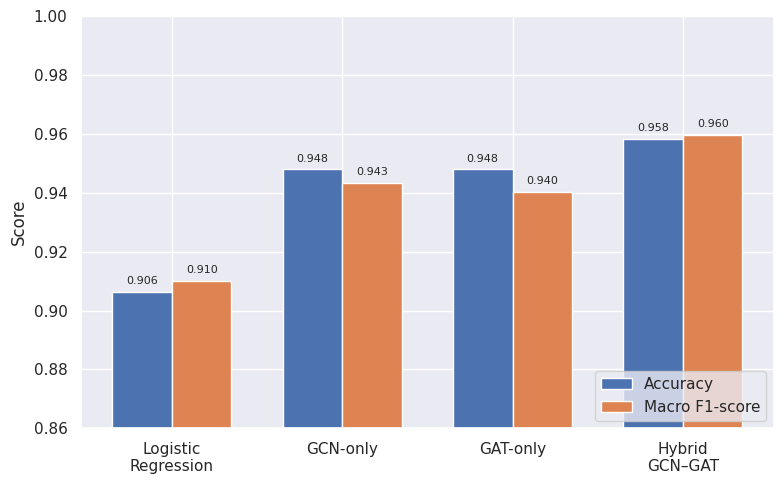

In [101]:
import matplotlib.pyplot as plt
import numpy as np

# Ablation study results
models = ["Logistic\nRegression", "GCN-only", "GAT-only", "Hybrid\nGCN–GAT"]
accuracy = [0.9062, 0.9479, 0.9479, 0.9583]
macro_f1 = [0.9102, 0.9432, 0.9403, 0.9596]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

acc_bars = plt.bar(x - width/2, accuracy, width,
                   label="Accuracy", color="#4C72B0")
f1_bars  = plt.bar(x + width/2, macro_f1, width,
                   label="Macro F1-score", color="#DD8452")

plt.ylabel("Score")
plt.ylim(0.86, 1.0)
plt.xticks(x, models)

plt.legend(loc="lower right")

for bars in [acc_bars, f1_bars]:
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.002,
                 f"{height:.3f}", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()
